In [1]:
!pip install ortools folium pandas numpy


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29.8/29.8 MB 27.7 MB/s  0:00:01


In [2]:
import pandas as pd
import numpy as np
import folium

from ortools.constraint_solver import (
    pywrapcp,
    routing_enums_pb2
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
import pandas as pd

students = {
    'Student_ID': range(1, 11),
    'Student_Name': [
        'Student_1', 'Student_2', 'Student_3',
        'Student_4', 'Student_5', 'Student_6',
        'Student_7', 'Student_8', 'Student_9',
        'Student_10'
    ],
    'Pickup_Location': [
        'Gandhipuram', 'RS Puram', 'Peelamedu',
        'Saibaba Colony', 'Singanallur',
        'Saravanampatti', 'Hope College',
        'Town Hall', 'Vadavalli', 'Ganapathy'
    ],
    'Latitude': [
        11.0180, 11.0100, 11.0240,
        11.0270, 10.9980, 11.0780,
        11.0250, 10.9950, 11.0300, 11.0420
    ],
    'Longitude': [
        76.9670, 76.9550, 77.0020,
        76.9500, 77.0150, 76.9950,
        77.0100, 76.9610, 76.9400, 76.9700
    ]
}

df = pd.DataFrame(students)

print(df)

   Student_ID Student_Name Pickup_Location  Latitude  Longitude
0           1    Student_1     Gandhipuram    11.018     76.967
1           2    Student_2        RS Puram    11.010     76.955
2           3    Student_3       Peelamedu    11.024     77.002
3           4    Student_4  Saibaba Colony    11.027     76.950
4           5    Student_5     Singanallur    10.998     77.015
5           6    Student_6  Saravanampatti    11.078     76.995
6           7    Student_7    Hope College    11.025     77.010
7           8    Student_8       Town Hall    10.995     76.961
8           9    Student_9       Vadavalli    11.030     76.940
9          10   Student_10       Ganapathy    11.042     76.970


In [4]:
buses = {
    'Bus_ID': ['Bus_1', 'Bus_2', 'Bus_3'],
    'Capacity': [4, 4, 4]
}

bus_df = pd.DataFrame(buses)

display(bus_df)

,Bus_ID,Capacity
0,Bus_1,4
1,Bus_2,4
2,Bus_3,4


In [7]:
# School location
school_lat = 11.0168
school_lon = 76.9558

# Create map
school_map = folium.Map(
    location=[school_lat, school_lon],
    zoom_start=12,
    tiles=None
)

folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}",
    attr="Esri",
    name="Street Map"
).add_to(school_map)

# Mark school location
folium.Marker(
    [school_lat, school_lon],
    popup="School",
    tooltip="School Location",
    icon=folium.Icon(color="red", icon="home")
).add_to(school_map)

# Mark all student pickup locations
for index, row in df.iterrows():
    folium.Marker(
        [row['Latitude'], row['Longitude']],
        popup=row['Student_Name'] + " - " + row['Pickup_Location'],
        tooltip=row['Pickup_Location'],
        icon=folium.Icon(color="blue", icon="user")
    ).add_to(school_map)

# Display map
school_map

In [8]:
from math import radians, sin, cos, sqrt, atan2

def calculate_distance(lat1, lon1, lat2, lon2):

    R = 6371

    lat1, lon1, lat2, lon2 = map(
        radians, [lat1, lon1, lat2, lon2]
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = sin(dlat/2)**2 + cos(lat1) * cos(lat2) * sin(dlon/2)**2

    c = 2 * atan2(sqrt(a), sqrt(1-a))

    return R * c


df['Distance_from_School'] = df.apply(
    lambda row: calculate_distance(
        school_lat, school_lon,
        row['Latitude'], row['Longitude']
    ),
    axis=1
)

display(df[['Student_ID', 'Pickup_Location',
            'Distance_from_School']])

,Student_ID,Pickup_Location,Distance_from_School
0,1,Gandhipuram,1.229691
1,2,RS Puram,0.761151
2,3,Peelamedu,5.105632
3,4,Saibaba Colony,1.298890
4,5,Singanallur,6.791374
5,6,Saravanampatti,8.038137
6,7,Hope College,5.985474
7,8,Town Hall,2.489611
8,9,Vadavalli,2.264538
9,10,Ganapathy,3.202143


In [9]:
# Combine school and student locations

locations = [(school_lat, school_lon)]

for index, row in df.iterrows():
    locations.append((row['Latitude'], row['Longitude']))

# Create distance matrix

distance_matrix = []

for loc1 in locations:
    row_distances = []

    for loc2 in locations:
        distance = calculate_distance(
            loc1[0], loc1[1],
            loc2[0], loc2[1]
        )

        row_distances.append(round(distance, 2))

    distance_matrix.append(row_distances)

# Convert into DataFrame

distance_df = pd.DataFrame(distance_matrix)

print("Distance Matrix:")
display(distance_df)

Distance Matrix:


,0,1,2,3,4,5,6,7,8,9,10
0,0.00,1.23,0.76,5.11,1.30,6.79,8.04,5.99,2.49,2.26,3.20
1,1.23,0.00,1.58,3.88,2.11,5.69,7.34,4.76,2.64,3.23,2.69
2,0.76,1.58,0.00,5.36,1.97,6.68,8.73,6.23,1.79,2.76,3.92
3,5.11,3.88,5.36,0.00,5.69,3.22,6.05,0.88,5.52,6.80,4.03
4,1.30,2.11,1.97,5.69,0.00,7.79,7.50,6.55,3.76,1.14,2.75
5,6.79,5.69,6.68,3.22,7.79,0.00,9.16,3.05,5.90,8.93,6.93
6,8.04,7.34,8.73,6.05,7.50,9.16,0.00,6.12,9.95,8.03,4.84
7,5.99,4.76,6.23,0.88,6.55,3.05,6.12,0.00,6.30,7.66,4.76
8,2.49,2.64,1.79,5.52,3.76,5.90,9.95,6.30,0.00,4.52,5.32
9,2.26,3.23,2.76,6.80,1.14,8.93,8.03,7.66,4.52,0.00,3.54


In [10]:
from ortools.constraint_solver import pywrapcp
from ortools.constraint_solver import routing_enums_pb2

# Number of buses and students
num_vehicles = len(bus_df)
num_locations = len(locations)

# Distance matrix in meters
distance_data = [
    [int(distance * 1000) for distance in row]
    for row in distance_matrix
]

# Bus capacities
bus_capacities = bus_df['Capacity'].tolist()

# Create routing manager
manager = pywrapcp.RoutingIndexManager(
    num_locations,
    num_vehicles,
    0
)

routing = pywrapcp.RoutingModel(manager)

# Distance callback
def distance_callback(from_index, to_index):

    from_node = manager.IndexToNode(from_index)
    to_node = manager.IndexToNode(to_index)

    return distance_data[from_node][to_node]

transit_callback = routing.RegisterTransitCallback(
    distance_callback
)

routing.SetArcCostEvaluatorOfAllVehicles(
    transit_callback
)

# Student demand
def demand_callback(from_index):

    node = manager.IndexToNode(from_index)

    if node == 0:
        return 0

    return 1

demand_callback_index = routing.RegisterUnaryTransitCallback(
    demand_callback
)

# Capacity constraint
routing.AddDimensionWithVehicleCapacity(
    demand_callback_index,
    0,
    bus_capacities,
    True,
    "Capacity"
)

# Search strategy
search_parameters = pywrapcp.DefaultRoutingSearchParameters()

search_parameters.first_solution_strategy = (
    routing_enums_pb2.FirstSolutionStrategy.PATH_CHEAPEST_ARC
)

search_parameters.local_search_metaheuristic = (
    routing_enums_pb2.LocalSearchMetaheuristic.GUIDED_LOCAL_SEARCH
)

search_parameters.time_limit.seconds = 10

# Solve
solution = routing.SolveWithParameters(search_parameters)

# Display results
if solution:

    for vehicle_id in range(num_vehicles):

        index = routing.Start(vehicle_id)
        route = []
        total_distance = 0

        while not routing.IsEnd(index):

            node = manager.IndexToNode(index)

            if node == 0:
                route.append("School")
            else:
                route.append(f"Student_{node}")

            previous_index = index
            index = solution.Value(
                routing.NextVar(index)
            )

            total_distance += routing.GetArcCostForVehicle(
                previous_index, index, vehicle_id
            )

        route.append("School")

        print(f"\nBus {vehicle_id + 1}")
        print("Route:", " -> ".join(route))
        print("Distance:", round(total_distance / 1000, 2), "km")

else:
    print("No solution found")


Bus 1
Route: School -> Student_2 -> Student_8 -> School
Distance: 5.04 km

Bus 2
Route: School -> Student_1 -> Student_3 -> Student_7 -> Student_5 -> School
Distance: 15.83 km

Bus 3
Route: School -> Student_4 -> Student_9 -> Student_6 -> Student_10 -> School
Distance: 18.51 km


In [11]:
# Create a new map
route_map = folium.Map(
    location=[school_lat, school_lon],
    zoom_start=12,
    tiles=None
)

folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}",
    attr="Esri"
).add_to(route_map)

# Bus route colours
colors = ['blue', 'green', 'purple']

if solution:

    for vehicle_id in range(num_vehicles):

        index = routing.Start(vehicle_id)
        route_coordinates = []

        while not routing.IsEnd(index):

            node = manager.IndexToNode(index)

            lat, lon = locations[node]
            route_coordinates.append((lat, lon))

            index = solution.Value(
                routing.NextVar(index)
            )

        # Add school as final destination
        route_coordinates.append((school_lat, school_lon))

        # Draw bus route
        folium.PolyLine(
            route_coordinates,
            color=colors[vehicle_id],
            weight=5,
            opacity=0.8,
            tooltip=f"Bus {vehicle_id + 1}"
        ).add_to(route_map)

# School marker
folium.Marker(
    [school_lat, school_lon],
    popup="School",
    icon=folium.Icon(color="red", icon="home")
).add_to(route_map)

# Student markers
for _, row in df.iterrows():

    folium.CircleMarker(
        [row['Latitude'], row['Longitude']],
        radius=6,
        popup=row['Student_Name'],
        color='black',
        fill=True,
        fill_color='orange'
    ).add_to(route_map)

route_map

In [12]:
bus_results = []

for vehicle_id in range(num_vehicles):

    index = routing.Start(vehicle_id)
    total_distance = 0
    student_count = 0

    while not routing.IsEnd(index):

        node = manager.IndexToNode(index)

        if node != 0:
            student_count += 1

        previous_index = index

        index = solution.Value(
            routing.NextVar(index)
        )

        total_distance += routing.GetArcCostForVehicle(
            previous_index,
            index,
            vehicle_id
        )

    bus_results.append({
        'Bus_ID': f'Bus_{vehicle_id + 1}',
        'Students': student_count,
        'Capacity': bus_capacities[vehicle_id],
        'Distance_KM': round(total_distance / 1000, 2)
    })

results_df = pd.DataFrame(bus_results)

display(results_df)

print("Total Students:", results_df['Students'].sum())

print(
    "Total Distance:",
    round(results_df['Distance_KM'].sum(), 2),
    "KM"
)

,Bus_ID,Students,Capacity,Distance_KM
0,Bus_1,2,4,5.04
1,Bus_2,4,4,15.83
2,Bus_3,4,4,18.51


Total Students: 10
Total Distance: 39.38 KM


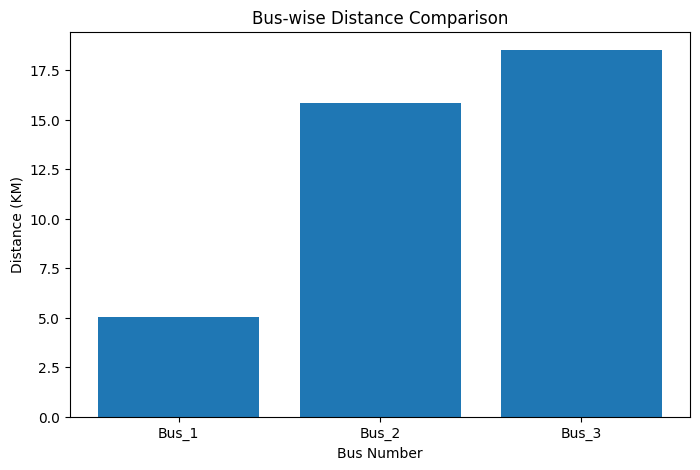

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    results_df['Bus_ID'],
    results_df['Distance_KM']
)

plt.title("Bus-wise Distance Comparison")
plt.xlabel("Bus Number")
plt.ylabel("Distance (KM)")

plt.show()

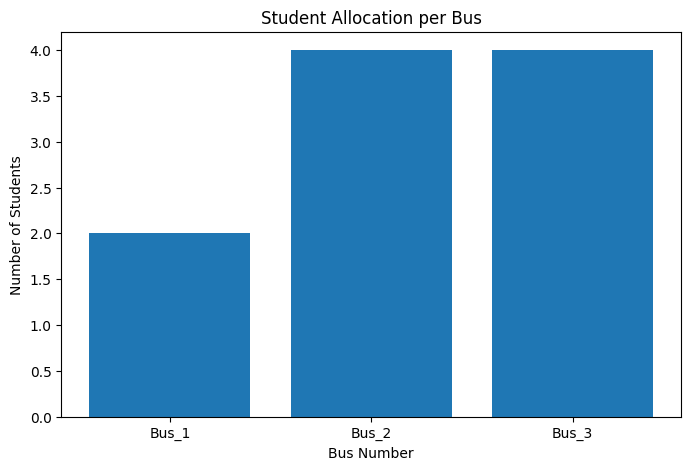

In [14]:
plt.figure(figsize=(8, 5))

plt.bar(
    results_df['Bus_ID'],
    results_df['Students']
)

plt.title("Student Allocation per Bus")
plt.xlabel("Bus Number")
plt.ylabel("Number of Students")

plt.show()

In [15]:
print("SCHOOL TRANSPORT OPTIMIZATION REPORT")
print("------------------------------------")

print("Total Students:",
      results_df['Students'].sum())

print("Total Buses:",
      len(results_df))

print("Total Distance:",
      round(results_df['Distance_KM'].sum(), 2),
      "KM")

print("\nBus Details:")

display(results_df)

SCHOOL TRANSPORT OPTIMIZATION REPORT
------------------------------------
Total Students: 10
Total Buses: 3
Total Distance: 39.38 KM

Bus Details:


,Bus_ID,Students,Capacity,Distance_KM
0,Bus_1,2,4,5.04
1,Bus_2,4,4,15.83
2,Bus_3,4,4,18.51


In [16]:
!pip install plotly

In [17]:
import plotly.express as px
import plotly.graph_objects as go
from IPython.display import display

# Project Summary
total_students = results_df['Students'].sum()
total_buses = len(results_df)
total_distance = results_df['Distance_KM'].sum()

print("SCHOOL TRANSPORT ROUTE OPTIMIZATION")
print("-----------------------------------")
print("Total Students:", total_students)
print("Total Buses:", total_buses)
print("Total Distance:", round(total_distance, 2), "KM")

# Student Allocation Chart
fig1 = px.bar(
    results_df,
    x='Bus_ID',
    y='Students',
    color='Bus_ID',
    title='Student Allocation by Bus'
)

fig1.show()

# Distance Comparison Chart
fig2 = px.pie(
    results_df,
    names='Bus_ID',
    values='Distance_KM',
    title='Bus-wise Distance Distribution'
)

fig2.show()

# Capacity Utilization
fig3 = px.bar(
    results_df,
    x='Bus_ID',
    y='Students',
    color='Bus_ID',
    title='Bus Capacity Utilization',
    hover_data=['Capacity']
)

fig3.show()

SCHOOL TRANSPORT ROUTE OPTIMIZATION
-----------------------------------
Total Students: 10
Total Buses: 3
Total Distance: 39.38 KM


In [18]:
df.to_csv("student_dataset.csv", index=False)

from google.colab import files
files.download("student_dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [19]:
bus_df.to_csv("bus_dataset.csv", index=False)

files.download("bus_dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:
distance_df.to_csv("distance_matrix.csv", index=False)

files.download("distance_matrix.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:
results_df.to_csv("optimized_bus_results.csv", index=False)

files.download("optimized_bus_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [22]:
route_map.save("school_bus_routes.html")

files.download("school_bus_routes.html")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>